# Desarrollo 03: lago Owasco, la segunda mejora del algoritmo

El notebook 02 dejo un metodo con memoria de la mira seca, probado en un lago con reflejo. Aqui se sigue la regla de esta carpeta: **se copia ese notebook cambiando solo la configuracion, se mira que falla, y se cambia solo lo que el fallo obliga**.

**Resultado.** En las 6 secciones (226 fotos, 137 con lectura de la v3), **la v3 da un error absoluto medio de 0.68 cm y 97.1 % en +-2 cm**; la copia sin cambios da 8.11 cm y 11.4 % con ese mismo cero. En la **serie completa, la v3 da 1.55 cm, 92.2 % en +-2 cm y 94.8 % en +-5 cm** (2579 fotos). El mayor fallo aparecio al abrir la referencia y no se reajusto: **de diciembre a febrero, con el lago bajo la placa, hay 115 lecturas falsas**, de mas de 10 cm, y 109 son el borde de la nieve acumulada, que el metodo toma por agua. Sin esos tres meses, solo como dato informativo: 0.56 cm y 96.5 %. Con la referencia solo se estima una constante de cero. **En Meguro y China no cambia ninguna lectura** (0 de 53 y 0 de 234), con los valores neutros. No es una prueba del todo a ciegas: seccion 4.2.

| Parte | |
|---|---|
| 1. Copia del notebook 02 | mismo codigo, solo cambia la configuracion. Tabla de valores China / Owasco |
| 2. Problemas | que salio mal, con figuras y su causa, y que no dio problema |
| 3. Cambios al codigo | cada cambio con su fallo y su diff literal; lista de lineas comprobada contra el notebook 02 |
| 4. Resultados en Owasco | por seccion, v2 y v3 (tabla principal), serie completa aparte, video |
| 5. Comprobacion de los casos anteriores | el mismo codigo v3 en Meguro y en China, foto por foto |
| 6. Limitaciones | que queda sin resolver |

**De donde sale cada numero.** Las partes 1 a 3 y la tabla principal se calculan solo sobre **6 secciones** de la serie. La **serie completa** (4790 fotos) es una validacion final de la v3 y se da aparte, en la seccion 4.3. **Las dos dicen cosas distintas:** las secciones no recogen el fallo de la nieve, y por eso hace falta la serie.

# 1. Copia del notebook 02

## 1.1 Preparacion y datos

**Datos.** Camara de la red HIVIS del Servicio Geologico de Estados Unidos (USGS), sobre la mira de la estacion 04235396, lago Owasco, Nueva York: 4790 fotos de 1520 x 2688 px, aproximadamente una por hora de dia, del 23-sep-2025 al 19-oct-2026. La mira son dos placas en pies atornilladas a un poste: la de arriba de 16.9 a 13.6 ft y la de abajo de 13.3 a 10.7 ft. El agua se mueve en la de abajo. La referencia es la cota oficial del lago, cada 15 min, y **solo se abre en la seccion 4.2**.

**Las secciones.** Son bloques continuos de la serie, sin quitar ninguna foto de dentro. **Se eligieron solo mirando las imagenes**, en hojas con una foto de cada dia, con la regla "el primer bloque de tres dias en que aparece esa condicion":

| Seccion | Bloque | Como se eligio |
|---|---|---|
| agua transparente | 24 a 26-sep-2025 | el agua cubre el pie de la placa y se ve la placa debajo: los primeros dias de la serie |
| sin agua, con nieve | 22 a 24-ene-2026 | la primera nieve que dura varios dias, con el agua bajo la placa |
| agua entrando en la placa | 8 a 10-mar-2026 | el primer regreso del agua a la placa tras el invierno |
| lente empanada | 1 a 3-abr-2026 | los primeros tres dias seguidos con la lente empanada |
| agua alta, placa verde | 13 a 15-may-2026 | los primeros dias con la placa cubierta de algas y el agua arriba |
| cambio de encuadre | 12 a 14-sep-2026 | el primer bloque que cruza un cambio de encuadre entre dos fotos nitidas |

**Lo que se sabia antes de elegir.** Esta camara ya se conocia, incluidos resultados previos, asi que la prueba no es del todo a ciegas (seccion 4.2). Para no elegir por resultado se uso la regla "el primero", y las secciones no se cambiaron despues de abrir la referencia.

Con `SOLO_SECCIONES = True` el notebook corre en pocos minutos y lee la serie completa de un CSV guardado; con `False` la vuelve a medir.

In [1]:
import ast
import difflib
import json
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = ventanas, amarillo = marcas y lectura a ojo
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

SOLO_SECCIONES = True     # True: solo las secciones, la serie completa se lee del CSV guardado. False: se vuelve a medir la serie completa

DATOS = os.path.join("..", "02_usgs_hivis_owasco", "datos")
CARPETA_FOTOS = os.path.join(DATOS, "fotos")
CSV_REFERENCIA = os.path.join(DATOS, "referencia_usgs.csv")     # solo se abre en la seccion 4.2
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (0, 0, 0, 0)                # x0, y0, x1, y1: en este ejemplo no hay nivel impreso que tapar
PIE = 30.48                               # la mira esta en pies; por dentro todo va en cm de mira


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # ..._2025-12-23T17-00-06Z.jpg -> 2025-12-23 17:00:06 (UTC)
    return datetime.strptime(os.path.basename(archivo).split("___")[1][:19], "%Y-%m-%dT%H-%M-%S")


fotos = sorted(f for f in os.listdir(CARPETA_FOTOS) if f.endswith(".jpg"))
print("%d fotos, de %s a %s (UTC)" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

# >>> AJUSTABLE <<< las secciones: bloques continuos, elegidos solo con la imagen
SECCIONES = {"agua transparente": ("2025-09-24 00:00", "2025-09-26 23:59"),
             "sin agua, con nieve": ("2026-01-22 00:00", "2026-01-24 23:59"),
             "agua entrando en la placa": ("2026-03-08 00:00", "2026-03-10 23:59"),
             "lente empanada": ("2026-04-01 00:00", "2026-04-03 23:59"),
             "agua alta, placa verde": ("2026-05-13 00:00", "2026-05-15 23:59"),
             "cambio de encuadre": ("2026-09-12 00:00", "2026-09-14 23:59")}


def seccion_de(archivo):
    h = hora_de(archivo)
    for nombre, (t0, t1) in SECCIONES.items():
        if pd.Timestamp(t0) <= h <= pd.Timestamp(t1):
            return nombre
    return None


fotos_s = [a for a in fotos if seccion_de(a) is not None]
print("En las secciones: %d fotos" % len(fotos_s), {s: sum(seccion_de(a) == s for a in fotos_s) for s in SECCIONES})

4790 fotos, de 2025-09-23 20:00:36 a 2026-10-19 17:00:07 (UTC)
En las secciones: 226 fotos {'agua transparente': 24, 'sin agua, con nieve': 35, 'agua entrando en la placa': 40, 'lente empanada': 45, 'agua alta, placa verde': 49, 'cambio de encuadre': 33}


## 1.2 Una foto

Dos placas en un poste de madera, vistas con gran angular desde arriba y de lado. El agua es transparente: bajo la linea de agua se sigue viendo la placa, algo mas oscura y verdosa. No hay reflejo de la mira.

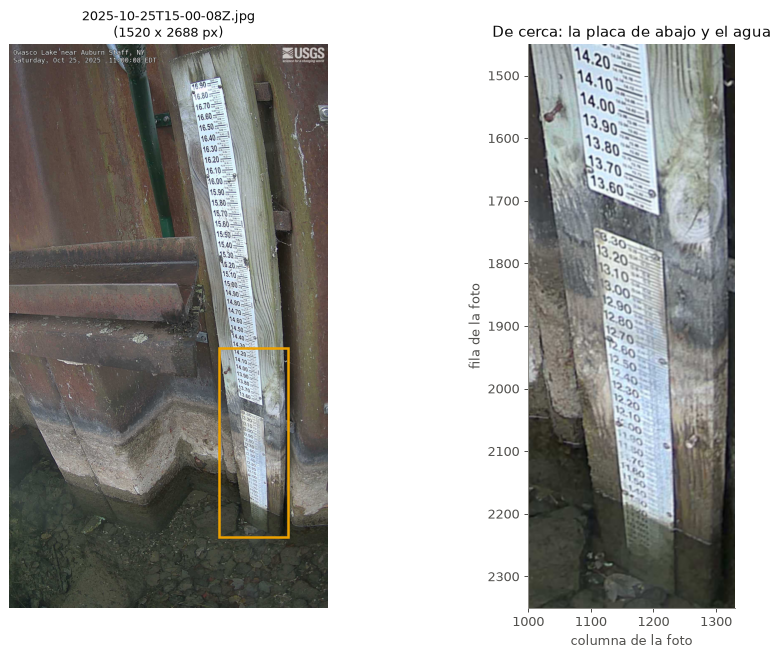

In [2]:
FOTO = "NY_Owasco_Lake_near_Auburn_Staff___2025-10-25T15-00-08Z.jpg"     # la foto con la que se explica el metodo
img = leer(FOTO)

fig, ax = plt.subplots(1, 2, figsize=(11, 7.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s\n(%d x %d px)" % (FOTO.split("___")[1], img.shape[1], img.shape[0]), color=TINTA, fontsize=10)
ax[0].add_patch(Rectangle((1000, 1450), 330, 900, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[1450:2350, 1000:1330]), extent=[1000, 1330, 2350, 1450], interpolation="bicubic")
ax[1].set_title("De cerca: la placa de abajo y el agua", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()

## 1.3 Configuracion: cuatro puntos y dos niveles

Igual que en los notebooks anteriores: a mano, una vez, sobre la foto de agua mas baja. Son los bordes de la placa y dos marcas conocidas, 14.0 y 11.0 ft. El codigo es el mismo: toma cada marca en una fila y los bordes en esa misma fila.

**Estos valores a mano ya existian** y se hicieron conociendo la referencia de esta camara, cosa que se declara en la seccion 4.2. Aqui se comprueban sobre la foto, y las marcas de control de 1.5 dicen si son buenos.

Esquinas: sup_izq (1080.6, 1562.0), sup_der (1202.7, 1562.0), inf_der (1230.9, 2230.0), inf_izq (1151.9, 2230.0)


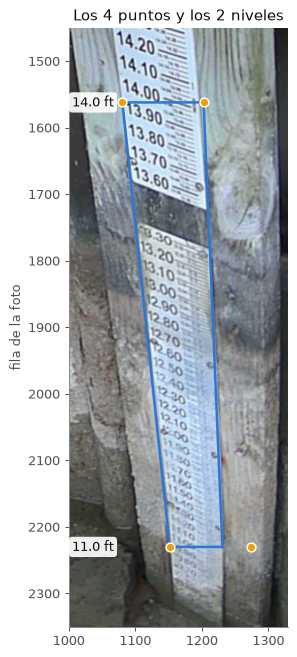

In [3]:
# >>> AJUSTABLE <<< (x, fila) de cada borde de la placa, leidos a ojo sobre ampliaciones de la foto de agua mas baja
BORDE_IZQ = [(1106, 1800), (1154, 2250)]
BORDE_DER = [(1214, 1830), (1233, 2280)]

# >>> AJUSTABLE <<< dos niveles conocidos (cm de mira) y la fila donde estan, leidos a ojo
NIVEL_SUP, FILA_SUP = 14.0 * PIE, 1562.0        # marca de 14.0 ft
NIVEL_INF, FILA_INF = 11.0 * PIE, 2230.0        # marca de 11.0 ft


def recta_por(puntos):
    (xa, ya), (xb, yb) = puntos
    return lambda y: xa + (np.asarray(y, float) - ya) * (xb - xa) / (yb - ya)


x_izq, x_der = recta_por(BORDE_IZQ), recta_por(BORDE_DER)
SUP_IZQ, SUP_DER = (float(x_izq(FILA_SUP)), FILA_SUP), (float(x_der(FILA_SUP)), FILA_SUP)
INF_DER, INF_IZQ = (float(x_der(FILA_INF)), FILA_INF), (float(x_izq(FILA_INF)), FILA_INF)
print("Esquinas: sup_izq (%.1f, %.1f), sup_der (%.1f, %.1f), inf_der (%.1f, %.1f), inf_izq (%.1f, %.1f)"
      % (*SUP_IZQ, *SUP_DER, *INF_DER, *INF_IZQ))

ref = leer("NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg")       # la foto de agua mas baja: toda la placa en seco
fig, a0 = plt.subplots(figsize=(5.4, 7.4))
a0.imshow(rgb(ref[1450:2350, 1000:1330]), extent=[1000, 1330, 2350, 1450], interpolation="bicubic")
a0.add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
for (x, y), texto in [(SUP_IZQ, "14.0 ft"), (INF_IZQ, "11.0 ft")]:
    a0.plot([x, x + (SUP_DER[0] - SUP_IZQ[0])], [y, y], "o", ms=7, mfc=AMARILLO, mec="white", mew=1.2)
    a0.text(1005, y, texto, color=TINTA, va="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a0.set_title("Los 4 puntos y los 2 niveles", color=TINTA); a0.set_ylabel("fila de la foto")
plt.tight_layout()

## 1.4 El tablero enderezado

`Tablero` es la clase del notebook 02, sin cambiar nada. Aqui 6 filas son 1 cm.

Tablero de 90 columnas x 668 filas


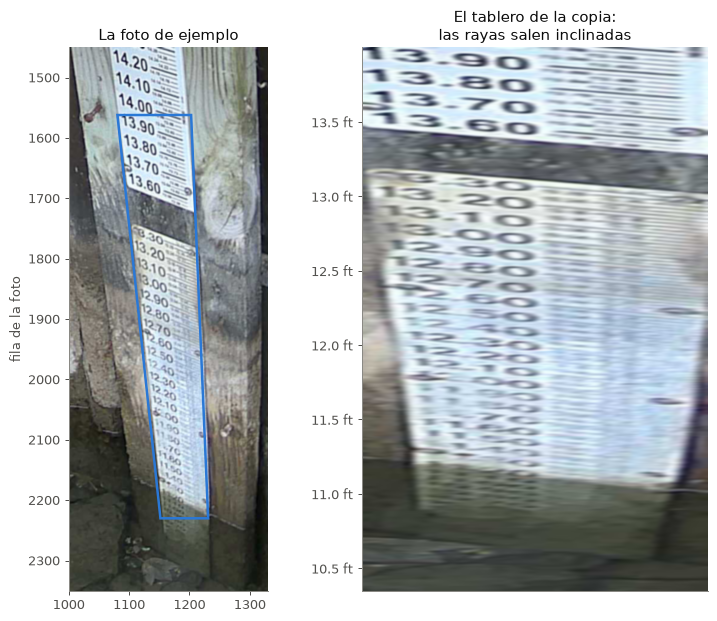

In [4]:
class Tablero:
    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo
    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        src = np.float64([sup_izq, sup_der, inf_der, inf_izq])
        dst = np.float64([[0, 0], [ancho_px, 0], [ancho_px, alto], [0, alto]])
        A = np.hstack([src, np.ones((4, 1))])
        self.M = np.array([np.linalg.lstsq(A, dst[:, i], rcond=None)[0] for i in (0, 1)])   # afin por minimos cuadrados
        self.M_inv = cv2.invertAffineTransform(self.M)
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        return cv2.warpAffine(img, self.M, self.tam, flags=cv2.INTER_LINEAR)

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        return self.M @ np.array([x, y, 1.0])       # punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        return self.M_inv @ np.array([col, fila, 1.0])   # punto del tablero -> (x, y) de la foto


PX_POR_CM = 6.0        # >>> AJUSTABLE <<< filas del tablero por cm (la escala de la camara va de ~4.6 a ~11.5 px/cm)
ANCHO = 90             # >>> AJUSTABLE <<< columnas del tablero (la placa mide de 80 a 125 px de ancho)
EXTRA_CM = 20.0        # >>> AJUSTABLE <<< cm por debajo del nivel inferior, para que entre lo que hay bajo la placa

T = Tablero(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
tablero = T.enderezar(img)
alto_total = T.tam[1]
niveles = np.arange(13.5, 10.4, -0.5)

fig, ax = plt.subplots(1, 2, figsize=(8.4, 7))
ax[0].imshow(rgb(img[1450:2350, 1000:1330]), extent=[1000, 1330, 2350, 1450], interpolation="bicubic")
ax[0].add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
ax[0].set_title("La foto de ejemplo", color=TINTA); ax[0].set_ylabel("fila de la foto")
ax[1].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
ax[1].set_yticks([T.fila_de(c * PIE) for c in niveles]); ax[1].set_yticklabels(["%.1f ft" % c for c in niveles])
ax[1].set_xticks([]); ax[1].set_title("El tablero de la copia:\nlas rayas salen inclinadas", color=TINTA)
plt.tight_layout()
print("Tablero de %d columnas x %d filas" % T.tam)

## 1.5 Marcas de control

Las marcas que no entran en el ajuste sirven para comprobar el tablero. Aqui cada marca se leyo en un punto de la foto, (x, fila), porque las rayas estan inclinadas.

In [5]:
# (x, fila) de la foto de cada marca, en ft, leidas a ojo. La de 14.0 y la de 11.0 son las del ajuste
MARCAS_CONTROL = {14.4: (1148, 1412), 13.6: (1175, 1695), 13.2: (1150, 1795), 12.5: (1165, 1967), 11.8: (1177, 2103)}

fuente = np.float32([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ])
alto_placa = (NIVEL_SUP - NIVEL_INF) * PX_POR_CM
destino = np.float32([[0, 0], [ANCHO, 0], [ANCHO, alto_placa], [0, alto_placa]])
H_libre = cv2.getPerspectiveTransform(fuente, destino)


def fila_homografia(H, x, y):
    return float(cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0][1])


filas_tabla = []
for c, (x, f) in sorted(MARCAS_CONTROL.items()):
    filas_tabla.append({"marca (ft)": c, "copia: medido - real (cm)": T.nivel_de(T.a_tablero(x, f)[1]) - c * PIE})
tabla_marcas = pd.DataFrame(filas_tabla).set_index("marca (ft)").round(2)
tabla_marcas

,copia: medido - real (cm)
marca (ft),
11.8,-7.00
12.5,-9.72
13.2,-7.51
13.6,-6.01
14.4,8.34


## 1.6 El rango de medida

Con el mismo criterio de los notebooks anteriores, mirando los extremos de la serie: **maximo 13.4 ft**, porque el agua llega como mucho al tope de la placa de abajo (13.3 ft) y por encima el poste nunca se moja; **minimo 10.75 ft**, el pie de la placa.

In [6]:
NIVEL_MINIMO = 10.75 * PIE          # >>> AJUSTABLE <<< cm: el pie de la placa; por debajo no hay lectura
NIVEL_MAX_AGUA = 13.4 * PIE         # >>> AJUSTABLE <<< cm: por encima la mira esta siempre seca en esta serie (visto en las fotos)
NIVEL_MIN_BUSQUEDA = 10.65 * PIE    # >>> AJUSTABLE <<< cm: se busca algo por debajo del minimo para detectar ese caso

## 1.7 El algoritmo, tal como quedo en el notebook 02

Nada cambia: el **espejo** (notebook 01), la **memoria de la mira seca**, el **registro** y las **fotos sin lectura** (notebook 02). Los parametros van en cm, asi que se dejan como estaban: solo cambian las columnas, por el ancho de esta mira.

In [7]:
VENTANA_CM = 8.0           # >>> AJUSTABLE <<< alto de cada ventana
H = int(VENTANA_CM * PX_POR_CM)
COLUMNAS = (3, 87)         # >>> AJUSTABLE <<< columnas del tablero que se comparan (dentro de la placa)


def ncc(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-9))


def ventanas(R, y, h=H, cols=COLUMNAS):
    # arriba volteada y abajo, listas para comparar
    return R[y - h:y, cols[0]:cols[1]][::-1], R[y:y + h, cols[0]:cols[1]]


def curva_espejo(R, filas, h=H, cols=COLUMNAS):
    return np.array([ncc(*ventanas(R, y, h, cols)) for y in filas])


def espejo(R, nivel_max=NIVEL_MAX_AGUA, nivel_min=NIVEL_MIN_BUSQUEDA, h=H):
    # devuelve la fila del tablero con mas parecido en espejo, su parecido, y la curva entera
    filas = np.arange(max(int(T.fila_de(nivel_max)), h), min(int(T.fila_de(nivel_min)), R.shape[0] - h) + 1)
    s = curva_espejo(R, filas, h)
    k = int(np.argmax(s))
    return int(filas[k]), float(s[k]), filas, s


FOTO_SECA = "NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg"   # >>> AJUSTABLE <<< la foto de agua mas baja. None: sin memoria
BANDA_CM = 2.0            # >>> AJUSTABLE <<< alto de la banda que se compara con la mira seca
FRACCION = 0.7            # >>> AJUSTABLE <<< por debajo de esta fraccion del parecido de la parte seca, la mira ya no se reconoce
HUECO_CM = 1.0            # >>> AJUSTABLE <<< tramo minimo sin parecido para dar el corte
REFINO_CM = 2.0           # >>> AJUSTABLE <<< el espejo busca en este tramo por debajo del corte
MARGEN_REGISTRO_CM = 2.5  # >>> AJUSTABLE <<< cuanto se puede mover la mira entre fotos
PARECIDO_SECO_MIN = 0.75  # >>> AJUSTABLE <<< por debajo, la parte que nunca se moja no se reconoce: foto sin lectura


def memorizar():
    # [v2] guarda la mira seca y la parte que nunca se moja: por encima del maximo del rango
    global SECA, PATRON, Z0, Z1, MARGEN
    SECA = None if FOTO_SECA is None else T.enderezar(gris(leer(FOTO_SECA)))
    MARGEN = int(MARGEN_REGISTRO_CM * T.px_por_cm)
    Z0, Z1 = MARGEN, int(T.fila_de(NIVEL_MAX_AGUA))
    PATRON = None if SECA is None else SECA[Z0:Z1, COLUMNAS[0]:COLUMNAS[1]]


def parecido_zona_seca(R):
    # [v2] parecido de la parte que nunca se moja con la mira seca. Sin foto seca: 1
    return 1.0 if SECA is None else ncc(R[Z0:Z1, COLUMNAS[0]:COLUMNAS[1]], PATRON)


def parecido_con_seca(R, filas):
    # [v2] NCC, fila a fila, de la banda que empieza en cada fila contra la misma banda de la mira seca
    c0, c1 = COLUMNAS
    hb = int(BANDA_CM * T.px_por_cm)
    return np.array([ncc(R[y:y + hb, c0:c1], SECA[y:y + hb, c0:c1]) for y in filas])


def primer_hueco(R, seco):
    # [v2] baja por la mira: primera fila de un tramo de HUECO_CM donde la banda ya no se parece a la mira seca
    n = max(int(HUECO_CM * T.px_por_cm), 1)
    filas = np.arange(int(T.fila_de(NIVEL_MAX_AGUA)), int(T.fila_de(NIVEL_MINIMO)) + 1)
    bajo = parecido_con_seca(R, filas) < FRACCION * seco
    for k in range(len(filas) - n + 1):
        if bajo[k:k + n].all():
            return int(filas[k])
    return None


def rango_busqueda(R, seco):
    # [v2] entre que niveles busca espejo. Sin foto seca, el rango de siempre, como en la v1
    if SECA is None:
        return NIVEL_MAX_AGUA, NIVEL_MIN_BUSQUEDA
    corte = primer_hueco(R, seco)
    if corte is None:          # no hay hueco: el agua esta en el minimo o por debajo
        return NIVEL_MINIMO, NIVEL_MIN_BUSQUEDA
    v = int(REFINO_CM * T.px_por_cm)
    return T.nivel_de(corte + 0.5), T.nivel_de(corte + v + 0.5)     # el 0.5 evita que el redondeo mueva una fila


def registrar(R):
    # [v2] cuanto se ha movido la mira: busca la parte que nunca se moja. Devuelve dx, dy (filas) y su parecido con la mira seca
    if SECA is None:
        return 0, 0, 1.0
    r = cv2.matchTemplate(R[:Z1 + MARGEN], PATRON, cv2.TM_CCOEFF_NORMED)
    _, seco, _, (x, y) = cv2.minMaxLoc(r)
    return x - COLUMNAS[0], y - Z0, seco


def alinear(R, dx, dy):
    # [v2] desplaza la foto para que sus filas coincidan con las de la mira seca
    if dx == 0 and dy == 0:
        return R
    return cv2.warpAffine(R, np.float32([[1, 0, -dx], [0, 1, -dy]]), (R.shape[1], R.shape[0]), flags=cv2.INTER_LINEAR)


def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    dx, dy, seco = registrar(R)                                 # [v2]
    R = alinear(R, dx, dy)                                      # [v2]
    fila, parecido, _, _ = espejo(R, *rango_busqueda(R, seco))  # [v2]
    nivel = T.nivel_de(fila) if seco >= PARECIDO_SECO_MIN else np.nan  # [v2]
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO),  # [v2]
            "dx": dx, "dy": dy, "parecido_seco": seco}  # [v2]


memorizar()

## 1.8 Lo que da la copia

`medir_secciones` y `marcar_saltos` son las del notebook 02. Se ejecuta, y **las lecturas se guardan en `salidas/03_v2_secciones.csv` antes de escribir ningun cambio**.

Para ver el resultado se usa un **quimograma**: el perfil vertical de la mira de cada foto, uno junto a otro. El tiempo va en horizontal y el nivel en vertical; los puntos son la lectura.

,fotos,sin_lectura,bajo_minimo,saltos,parecido_seco,parecido_espejo,dy_mediano
seccion,,,,,,,
agua transparente,24,1,0,2,0.94,0.33,1.0
"sin agua, con nieve",35,6,0,0,0.96,0.37,0.0
agua entrando en la placa,40,6,1,0,0.93,0.31,1.0
lente empanada,45,6,0,5,0.88,0.25,1.0
"agua alta, placa verde",49,6,0,2,0.91,0.20,2.0
cambio de encuadre,33,33,0,0,0.08,0.15,-4.0


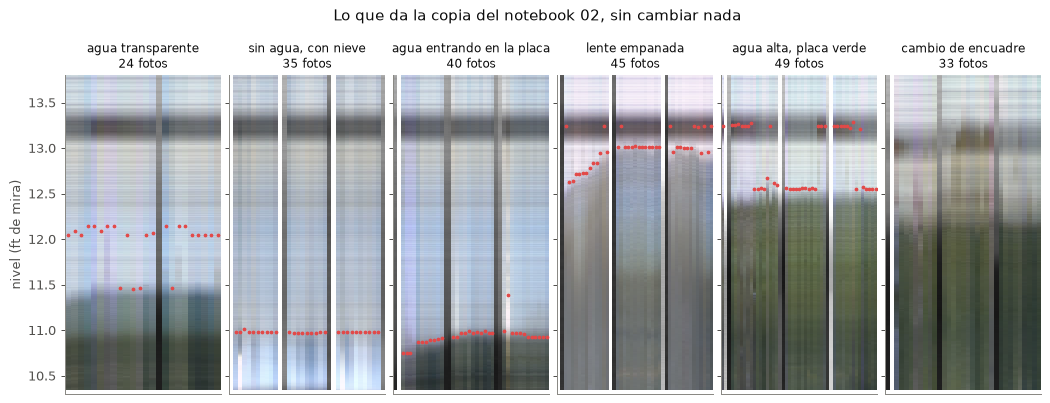

In [8]:
SALTO_CM = 3.0     # solo para contar saltos: el metodo no filtra nada


def marcar_saltos(serie):
    m = np.array([np.median(serie[max(i - 3, 0):i + 4]) for i in range(len(serie))])
    return np.abs(serie - m) > SALTO_CM


def medir_secciones():
    # recorre las fotos de las secciones, en paralelo, y marca los saltos dentro de cada bloque
    with ThreadPoolExecutor(8) as ex:
        d = pd.DataFrame(list(ex.map(medir_foto, fotos_s))).sort_values("hora").reset_index(drop=True)
    d["seccion"] = [seccion_de(a) for a in d.archivo]
    d["nivel_m"] = np.where(d.bajo_minimo, np.nan, d.nivel_bruto_cm / 100)
    d["salto"] = d.groupby("seccion").nivel_bruto_cm.transform(lambda s: marcar_saltos(s.values)).astype(bool)
    return d


def preparar_tiras(lista=None):
    # la mira de cada foto, enderezada con el tablero activo y en color: solo para dibujar
    def una(a):
        return a, T.enderezar(leer(a))
    with ThreadPoolExecutor(8) as ex:
        return dict(ex.map(una, fotos_s if lista is None else lista))


def dibujar_secciones(lecturas, tiras, titulo=None, alto=4.6, y0=10.3, y1=13.8):
    # un quimograma por seccion. lecturas: [(dataframe, color, tamano), ...]. tiras: {archivo: tira}
    fig, ax = plt.subplots(1, len(SECCIONES), figsize=(14, alto), sharey=True, gridspec_kw={"wspace": 0.05})
    for a, s in zip(ax, SECCIONES):
        lista = [x for x in fotos_s if seccion_de(x) == s]
        ps = [tiras[x][:, 8:ANCHO - 8].mean(1) for x in lista]     # los tableros de cada encuadre pueden tener distinto alto
        alto_k = max(len(p) for p in ps)
        K = np.stack([np.pad(p, ((0, alto_k - len(p)), (0, 0))) for p in ps], 1).astype(np.uint8)
        a.imshow(K[:, :, ::-1], extent=[0, K.shape[1], T.nivel_de(K.shape[0]) / PIE, T.nivel_sup / PIE], aspect="auto", interpolation="nearest")
        for d, color, ms in lecturas:
            ds = d.set_index("archivo").reindex(lista)
            a.plot(np.arange(len(lista)) + 0.5, ds.nivel_bruto_cm.where(~ds.bajo_minimo.astype(bool)) / PIE, ".", ms=ms, color=color)
        a.set_ylim(y0, y1); a.set_xticks([]); a.set_title("%s\n%d fotos" % (s, len(lista)), fontsize=9.5, color=TINTA)
    ax[0].set_ylabel("nivel (ft de mira)")
    if titulo:
        fig.suptitle(titulo, color=TINTA, y=1.04)


df_copia = medir_secciones()
df_copia.to_csv(os.path.join(SALIDAS, "03_v2_secciones.csv"), index=False, float_format="%.4f")
tiras_copia = preparar_tiras()
dibujar_secciones([(df_copia, ROJO, 4)], tiras_copia, "Lo que da la copia del notebook 02, sin cambiar nada")
df_copia.groupby("seccion", sort=False).agg(fotos=("archivo", "size"), sin_lectura=("nivel_bruto_cm", lambda s: int(s.isna().sum())), bajo_minimo=("bajo_minimo", "sum"),
                                            saltos=("salto", "sum"), parecido_seco=("parecido_seco", "median"), parecido_espejo=("parecido", "median"), dy_mediano=("dy", "median")).round(2)

## 1.9 Que cambio exactamente en esta copia

Se calcula leyendo el codigo de los dos notebooks, no a mano. Primero, los valores de configuracion, y luego que funciones son identicas, linea a linea, a la version final del notebook 02.

In [9]:
NB_02, NB_03 = "02_lago_china_primera_mejora.ipynb", "03_lago_owasco_segunda_mejora.ipynb"


def celdas_codigo(ruta):
    nb = json.load(open(ruta, encoding="utf-8"))
    return ["".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code"]


def definiciones(ruta):
    # funciones y clases de primer nivel, en orden: [(nombre, codigo), ...]
    salida = []
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, (ast.FunctionDef, ast.ClassDef)):
                salida.append((nodo.name, "\n".join(codigo.splitlines()[nodo.lineno - 1:nodo.end_lineno])))
    return salida


def asignaciones(ruta):
    # primer valor escrito para cada nombre en una asignacion de primer nivel: {nombre: texto}
    salida = {}
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, ast.Assign) and len(nodo.targets) == 1:
                obj, val = nodo.targets[0], nodo.value
                pares = zip(obj.elts, val.elts) if isinstance(obj, ast.Tuple) and isinstance(val, ast.Tuple) else [(obj, val)]
                for o, v in pares:
                    if isinstance(o, ast.Name):
                        salida.setdefault(o.id, ast.get_source_segment(codigo, v))
    return salida


defs_02, defs_03 = definiciones(NB_02), definiciones(NB_03)
a02, a03 = asignaciones(NB_02), asignaciones(NB_03)
CONFIGURACION = ["TEXTO_NIVEL", "BORDE_IZQ", "BORDE_DER", "NIVEL_SUP", "FILA_SUP", "NIVEL_INF", "FILA_INF", "PX_POR_CM", "ANCHO", "EXTRA_CM", "NIVEL_MINIMO", "NIVEL_MAX_AGUA", "NIVEL_MIN_BUSQUEDA",
                 "VENTANA_CM", "COLUMNAS", "FOTO_SECA", "BANDA_CM", "FRACCION", "HUECO_CM", "REFINO_CM", "MARGEN_REGISTRO_CM", "PARECIDO_SECO_MIN"]
tabla_config = pd.DataFrame([{"valor": n, "China": a02.get(n, "-"), "Owasco": a03.get(n, "-"), "igual": a02.get(n) == a03.get(n)} for n in CONFIGURACION]).set_index("valor")
pd.set_option("display.max_colwidth", 80)
display(tabla_config)

ULTIMA_02, PRIMERA_03 = {}, {}
for n, f in defs_02:
    ULTIMA_02[n] = f
for n, f in defs_03:
    PRIMERA_03.setdefault(n, f)
METODO = ["leer", "rgb", "gris", "recta_por", "Tablero", "fila_homografia", "ncc", "ventanas", "curva_espejo", "espejo", "memorizar", "parecido_zona_seca", "parecido_con_seca",
          "primer_hueco", "rango_busqueda", "registrar", "alinear", "medir_foto", "marcar_saltos", "medir_secciones"]
for n in METODO:
    print("%-20s %s" % (n, "identica a la version final del notebook 02" if ULTIMA_02[n] == PRIMERA_03[n] else "DISTINTA"))
    assert ULTIMA_02[n] == PRIMERA_03[n]
print("\nDistinta por el nombre de los archivos, no es del metodo:")
print("\n".join(l for l in difflib.unified_diff(ULTIMA_02["hora_de"].splitlines(), PRIMERA_03["hora_de"].splitlines(), "notebook 02", "esta copia", lineterm="", n=0)))

,China,Owasco,igual
valor,,,
TEXTO_NIVEL,"(0, 0, 0, 0)","(0, 0, 0, 0)",True
BORDE_IZQ,"[(2002, 1200), (1980, 1742)]","[(1106, 1800), (1154, 2250)]",False
BORDE_DER,"[(2056, 1200), (2033, 1742)]","[(1214, 1830), (1233, 2280)]",False
NIVEL_SUP,95.0,14.0 * PIE,False
FILA_SUP,1119.5,1562.0,False
NIVEL_INF,25.0,11.0 * PIE,False
FILA_INF,1762.0,2230.0,False
PX_POR_CM,9.0,6.0,False
ANCHO,54,90,False


leer                 identica a la version final del notebook 02
rgb                  identica a la version final del notebook 02
gris                 identica a la version final del notebook 02
recta_por            identica a la version final del notebook 02
Tablero              identica a la version final del notebook 02
fila_homografia      identica a la version final del notebook 02
ncc                  identica a la version final del notebook 02
ventanas             identica a la version final del notebook 02
curva_espejo         identica a la version final del notebook 02
espejo               identica a la version final del notebook 02
memorizar            identica a la version final del notebook 02
parecido_zona_seca   identica a la version final del notebook 02
parecido_con_seca    identica a la version final del notebook 02
primer_hueco         identica a la version final del notebook 02
rango_busqueda       identica a la version final del notebook 02
registrar            iden

# 2. Problemas

## 2.1 Lo que no da problema

- **La escala.** Ventanas y bandas van en cm, y sirven tal cual.
- **La unidad.** La mira esta en pies, pero el metodo trabaja en cm: es una constante.
- **Las fotos quemadas.** La parte seca no se reconoce y quedan sin lectura, con el cambio 3 del notebook 02 y sin codigo nuevo. En esta serie no hay fotos rotas.

## 2.2 Problema 1: el tablero no queda derecho

La camara es un gran angular que mira hacia abajo y de lado. **Las rayas salen inclinadas unos 20 grados y la escala cambia mucho de arriba a abajo**, de unos 350 a unos 140 px por pie. Con las esquinas tomadas en una misma fila, el tablero sale torcido: cada fila cruza varias rayas, y una fila ya no es un nivel. La tabla compara tres formas de enderezar en las marcas de control. Enderezar siguiendo las rayas ayuda, pero los lados paralelos dejan hasta 10 cm de error; hace falta perspectiva. En los notebooks 01 y 02 pasaba lo contrario, porque la mira era casi frontal.

,"copia, esquinas en una fila","esquinas sobre las rayas, lados paralelos","esquinas sobre las rayas, perspectiva"
marca (ft),,,
11.8,-7.00,-7.24,-0.52
12.5,-9.72,-10.30,-0.73
13.2,-7.51,-8.51,-0.14
13.6,-6.01,-5.62,-0.29
14.4,8.34,7.93,-0.05


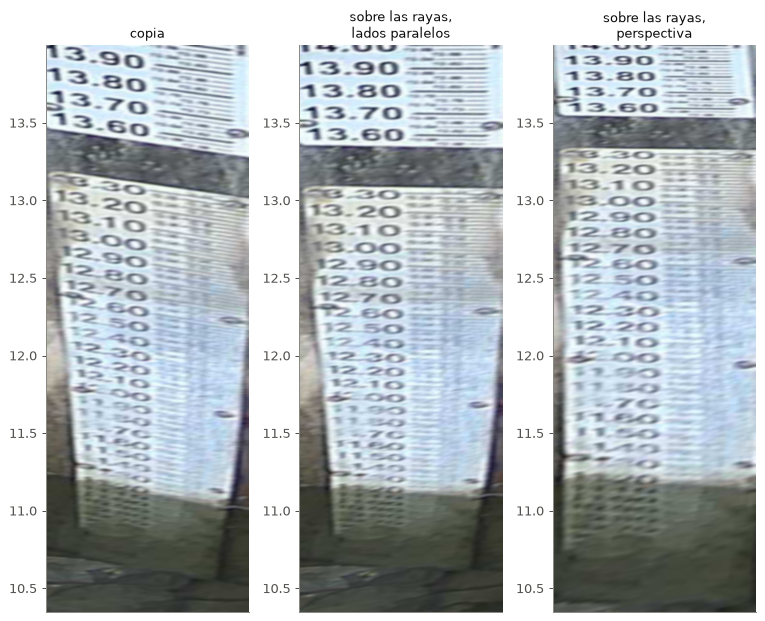

In [10]:
# Esquinas sobre las rayas: en la placa de abajo, los dos extremos de la raya de 14.0 ft y de la de 11.0 ft
SOBRE_RAYAS = ((1078.0, 1534.0), (1203.0, 1575.0), (1232.0, 2248.0), (1150.0, 2215.0))     # sup_izq, sup_der, inf_der, inf_izq

T_paralelos = Tablero(*SOBRE_RAYAS, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
H_rayas = cv2.getPerspectiveTransform(np.float32(SOBRE_RAYAS), destino)
filas_tabla = []
for c, (x, f) in sorted(MARCAS_CONTROL.items()):
    filas_tabla.append({"marca (ft)": c, "copia, esquinas en una fila": T.nivel_de(T.a_tablero(x, f)[1]) - c * PIE,
                        "esquinas sobre las rayas, lados paralelos": T.nivel_de(T_paralelos.a_tablero(x, f)[1]) - c * PIE,
                        "esquinas sobre las rayas, perspectiva": T.nivel_de(fila_homografia(H_rayas, x, f)) - c * PIE})
display(pd.DataFrame(filas_tabla).set_index("marca (ft)").round(2))

fig, ax = plt.subplots(1, 3, figsize=(8.6, 7), sharey=False)
ax[0].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic"); ax[0].set_title("copia", color=TINTA, fontsize=10)
ax[1].imshow(rgb(T_paralelos.enderezar(img)), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic"); ax[1].set_title("sobre las rayas,\nlados paralelos", color=TINTA, fontsize=10)
ax[2].imshow(rgb(cv2.warpPerspective(img, H_rayas, T.tam)), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic"); ax[2].set_title("sobre las rayas,\nperspectiva", color=TINTA, fontsize=10)
for a in ax:
    a.set_xticks([]); a.set_yticks([T.fila_de(c * PIE) for c in niveles]); a.set_yticklabels(["%.1f" % c for c in niveles])
plt.tight_layout()

## 2.3 Problema 2: la camara cambia de encuadre

La camara se movio varias veces. Una sola foto seca deja de servir: en la seccion "cambio de encuadre" la parte que nunca se moja casi no se parece a la foto seca, y el metodo se queda sin lectura. **No da un numero falso, pero tampoco mide.**

Seccion 'cambio de encuadre' en la copia: 33 fotos, 33 sin lectura, parecido de la parte seca mediano 0.08


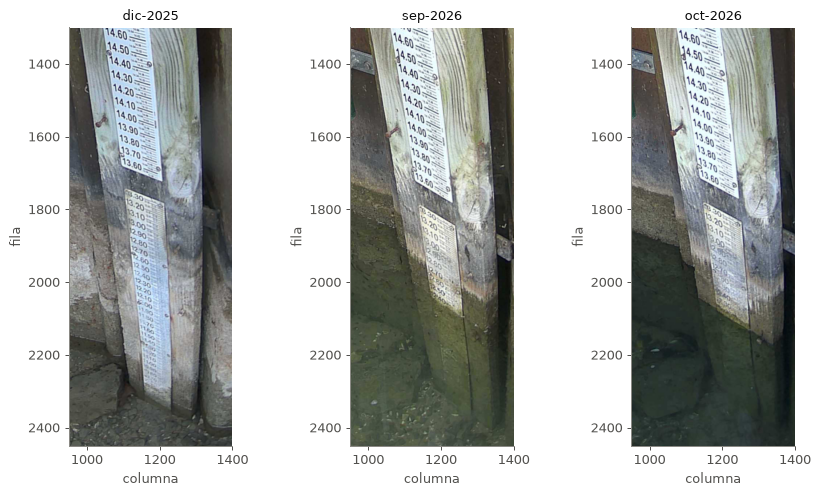

In [11]:
ej_encuadre = ["NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg", "NY_Owasco_Lake_near_Auburn_Staff___2026-09-01T17-00-07Z.jpg", "NY_Owasco_Lake_near_Auburn_Staff___2026-10-19T17-00-07Z.jpg"]
fig, ax = plt.subplots(1, 3, figsize=(9.6, 5.6))
for a, archivo, titulo in zip(ax, ej_encuadre, ["dic-2025", "sep-2026", "oct-2026"]):
    a.imshow(rgb(leer(archivo)[1300:2450, 950:1400]), extent=[950, 1400, 2450, 1300], interpolation="bilinear")
    a.set_title(titulo, color=TINTA, fontsize=10); a.set_xlabel("columna"); a.set_ylabel("fila")
plt.tight_layout()
c_ = df_copia[df_copia.seccion == "cambio de encuadre"]
print("Seccion 'cambio de encuadre' en la copia: %d fotos, %d sin lectura, parecido de la parte seca mediano %.2f" % (len(c_), c_.nivel_bruto_cm.isna().sum(), c_.parecido_seco.median()))

## 2.4 Problema 3: no hay reflejo

El agua es transparente y la camara mira desde arriba: bajo la linea de agua se ve **la propia placa**, no su reflejo. El espejo se queda sin nada que comparar. En la figura, con la mira ya bien enderezada para que se vea mejor, la curva de parecido en espejo no tiene un pico en el agua, que aqui esta en ~11.2 ft: el mayor esta en la mira seca. Los picos de la copia estan entre 0.2 y 0.4 de mediana, frente a 0.8 en el notebook 01.

**Lo que se mantiene es el contraste:** la placa seca es clara y bajo el agua es mas oscura. Ese escalon se ve en la foto, y es lo que se usara en 3.4.

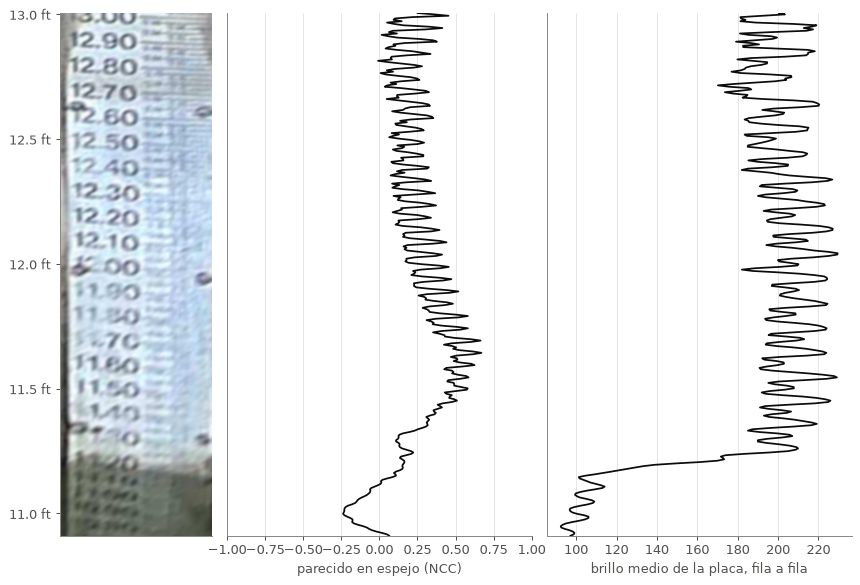

In [12]:
g_ej = cv2.warpPerspective(gris(img), H_rayas, T.tam)
filas_e = np.arange(int(T.fila_de(13.0 * PIE)), int(T.fila_de(10.9 * PIE)))
curva_e = curva_espejo(g_ej, filas_e)
col_e = g_ej[:, 15:75].mean(1)
fig, ax = plt.subplots(1, 3, figsize=(10, 6.6), sharey=True, gridspec_kw={"width_ratios": [0.5, 1, 1], "wspace": 0.06})
ax[0].imshow(rgb(cv2.warpPerspective(img, H_rayas, T.tam)), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic"); ax[0].set_xticks([])
ax[0].set_yticks([T.fila_de(c * PIE) for c in niveles]); ax[0].set_yticklabels(["%.1f ft" % c for c in niveles])
ax[1].plot(curva_e, filas_e, color=TINTA, lw=1.4); ax[1].set_xlim(-1, 1); ax[1].set_xlabel("parecido en espejo (NCC)"); ax[1].grid(axis="x", color=REJILLA, lw=0.8); ax[1].set_axisbelow(True)
ax[2].plot(col_e[filas_e], filas_e, color=TINTA, lw=1.4); ax[2].set_xlabel("brillo medio de la placa, fila a fila"); ax[2].grid(axis="x", color=REJILLA, lw=0.8); ax[2].set_axisbelow(True)
ax[0].set_ylim(filas_e[-1], filas_e[0])
for a in ax[1:]:
    a.tick_params(axis="y", length=0)
fig.subplots_adjust(left=0.1, right=0.98, top=0.97, bottom=0.09)

# 3. Cambios al codigo

## Cambios respecto a la version anterior

| # | Que cambia | Por que (fallo) | Seccion | Valor que deja la version anterior |
|---|---|---|---|---|
| 1 | **Perspectiva.** `Tablero` puede enderezar con los 4 puntos tomados sobre las rayas y una homografia | rayas inclinadas y escala variable (2.2) | 3.1 | `perspectiva=False` |
| 2 | **Varios encuadres.** Una configuracion por encuadre; en cada foto se usa la de mejor parecido de su parte seca | la camara se movio (2.3) | 3.2 | un solo encuadre |
| - | **Solo parametros, sin codigo:** columnas, umbral, hueco, control de parecido y minimo | se explican en 3.3 | 3.3 | |
| 3 | **Refino con el escalon.** Dentro del rango de la memoria, la fila es la del mayor oscurecimiento y no el espejo | no hay reflejo (2.4) | 3.4 | `REFINO = "espejo"` |

**Marcas.** Lo nuevo lleva `# [v3]` en el codigo. Sigue sin haber filtro temporal.

**Como se eligio sin referencia.** Se leyo a ojo la linea de agua, en la columna central de la placa, de 52 fotos repartidas por la serie, con un error de ~1 cm. **No es la referencia**: es solo una ayuda para decidir, porque una curva suave no prueba nada. Sus resultados salen en cada cambio.

**Orden real.** Los problemas y los cambios se probaron primero fuera de este notebook, sin referencia y sobre partes de la serie o sobre toda ella. Asi que la copia no se ejecuto antes de explorar: aqui se recogen en orden, y `03_v2_secciones.csv` sale de la copia sin cambios al ejecutar el notebook.

In [13]:
# Lectura a ojo de la linea de agua (ft de mira), columna central, +-0.03 ft. NO es la referencia: solo sirve para elegir sin abrirla
CONTROL_OJO = { "2025-09-30T16-00-06": 11.59, "2025-09-30T20-00-08": 11.59, "2025-10-10T16-00-09": 11.45, "2025-10-10T21-00-08": 11.45, "2025-10-25T15-00-08": 11.2, "2025-10-25T21-00-08": 11.2, "2025-11-05T16-00-04": 11.3, "2025-11-05T21-00-04": 11.28, "2025-11-20T16-00-05": 11.56, "2025-11-20T21-00-04": 11.53, "2025-12-02T16-00-12": 10.97, "2025-12-02T21-00-03": 10.97, "2026-03-12T16-00-13": 10.96, "2026-03-12T21-00-13": 10.96, "2026-03-16T16-00-03": 11.16, "2026-03-16T21-00-03": 11.11, "2026-03-20T16-00-04": 11.74, "2026-03-20T21-00-21": 11.77, "2026-03-26T16-00-03": 11.93, "2026-03-26T21-00-04": 11.89, "2026-04-07T16-00-04": 13.02, "2026-04-07T21-00-04": 13.03, "2026-04-15T16-00-04": 12.23, "2026-04-15T21-00-03": 12.23, "2026-04-25T16-00-05": 12.67, "2026-04-25T21-00-13": 12.69, "2026-05-05T16-00-06": 12.55, "2026-05-05T21-00-07": 12.57, "2026-05-10T16-00-05": 12.75, "2026-05-10T21-00-14": 12.73, "2026-05-20T16-00-15": 12.72, "2026-05-20T21-00-22": 12.72, "2026-05-28T16-00-13": 12.86, "2026-05-28T19-00-10": 12.85, "2026-06-02T16-00-13": 12.73, "2026-06-02T21-00-19": 12.72, "2026-06-08T16-00-05": 12.73, "2026-06-08T21-00-22": 12.72, "2026-06-15T16-00-04": 12.79, "2026-06-15T21-00-04": 12.78, "2026-08-15T16-00-07": 12.63, "2026-08-15T21-00-13": 12.53, "2026-08-25T15-00-07": 12.43, "2026-08-25T20-00-04": 12.43, "2026-09-05T16-00-21": 12.63, "2026-09-05T21-00-19": 12.66, "2026-09-20T16-00-08": 12.55, "2026-09-20T21-00-05": 12.49, "2026-10-01T16-00-08": 12.33, "2026-10-01T19-00-05": 12.32, "2026-10-15T16-00-06": 12.13, "2026-10-15T21-00-07": 12.14 }


def control_a_ojo(nombre, encuadre_de=None):
    # compara una configuracion con la lectura a ojo. encuadre_de: {archivo: encuadre}; si es None se usa el tablero activo
    errores = []
    for clave, ojo in CONTROL_OJO.items():
        a = "NY_Owasco_Lake_near_Auburn_Staff___%sZ.jpg" % clave
        if encuadre_de is not None:
            activar(encuadre_de(a))
        r = medir_foto(a)
        errores.append(r["nivel_bruto_cm"] - ojo * PIE)
    e = pd.Series(errores)
    return {"regla": nombre, "fotos con lectura": int(e.notna().sum()), "a menos de 2 cm": int((e.abs() <= 2).sum()), "error abs. medio (cm)": round(e.abs().mean(), 2), "peor (cm)": round(e.abs().max(), 1)}


control = [control_a_ojo("copia")]
pd.DataFrame(control).set_index("regla")

,fotos con lectura,a menos de 2 cm,error abs. medio (cm),peor (cm)
regla,,,,
copia,34,7,9.0,66.4


## 3.1 Cambio 1: la perspectiva

**El fallo.** El tablero sale torcido y con la escala mal (2.2).

**Que se agrega.** Sigue siendo la idea de los notebooks anteriores: cuatro puntos y una cuenta sencilla de filas a nivel. Lo que cambia es que los puntos se toman **sobre las rayas**: donde la raya de cada nivel corta los bordes de la placa, leidos con esos bordes, las marcas y la pendiente de las rayas medida junto a cada marca. Con `perspectiva=True` el tablero usa una homografia con esos cuatro puntos en lugar de lados paralelos. La conversion de fila a nivel no cambia. **Valor neutro:** con `perspectiva=False`, por defecto, todo sigue igual que en la v2, y la parte 5 lo comprueba.

--- notebook 02
+++ esta version
@@ -2,2 +2,2 @@
-    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo
-    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
+    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo. [v3] perspectiva=True: con homografia
+    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm, perspectiva=False):  # [v3]
@@ -10,0 +11 @@
+        self.H = cv2.getPerspectiveTransform(np.float32(src), np.float32(dst)) if perspectiva else None  # [v3]
@@ -13,0 +15,2 @@
+        if self.H is not None:  # [v3]
+            return cv2.warpPerspective(img, self.H, self.tam, flags=cv2.INTER_LINEAR)  # [v3]
@@ -22,0 +26,2 @@
+        if self.H is not None:  # [v3]
+            return cv2.perspectiveTransform(np.float64([[[x, y]]]), self.H)[0, 0]  # [v3]
@@ -25,0 +31,2 @@
+        if 

,fotos con lectura,a menos de 2 cm,error abs. medio (cm),peor (cm)
regla,,,,
copia,34,7,9.00,66.4
+ perspectiva,36,29,2.72,30.1


,medido - real (cm)
marca (ft),
11.8,-0.52
12.5,-0.73
13.2,-0.14
13.6,-0.29
14.4,-0.05


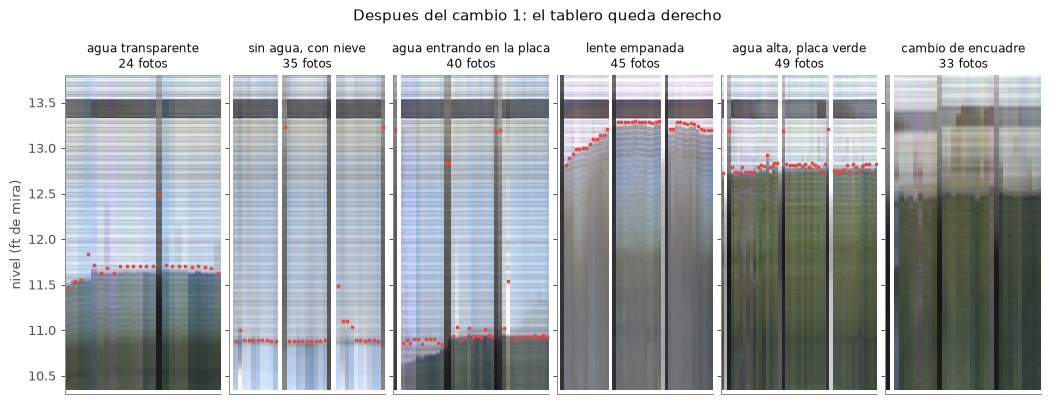

In [14]:
class Tablero:
    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo. [v3] perspectiva=True: con homografia
    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm, perspectiva=False):  # [v3]
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        src = np.float64([sup_izq, sup_der, inf_der, inf_izq])
        dst = np.float64([[0, 0], [ancho_px, 0], [ancho_px, alto], [0, alto]])
        A = np.hstack([src, np.ones((4, 1))])
        self.M = np.array([np.linalg.lstsq(A, dst[:, i], rcond=None)[0] for i in (0, 1)])   # afin por minimos cuadrados
        self.M_inv = cv2.invertAffineTransform(self.M)
        self.H = cv2.getPerspectiveTransform(np.float32(src), np.float32(dst)) if perspectiva else None  # [v3]
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        if self.H is not None:  # [v3]
            return cv2.warpPerspective(img, self.H, self.tam, flags=cv2.INTER_LINEAR)  # [v3]
        return cv2.warpAffine(img, self.M, self.tam, flags=cv2.INTER_LINEAR)

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        if self.H is not None:  # [v3]
            return cv2.perspectiveTransform(np.float64([[[x, y]]]), self.H)[0, 0]  # [v3]
        return self.M @ np.array([x, y, 1.0])       # punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        if self.H is not None:  # [v3]
            return cv2.perspectiveTransform(np.float64([[[col, fila]]]), np.linalg.inv(self.H))[0, 0]  # [v3]
        return self.M_inv @ np.array([col, fila, 1.0])   # punto del tablero -> (x, y) de la foto


T = Tablero(*SOBRE_RAYAS, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM, perspectiva=True)   # [v3]
memorizar()


def diff_literal(nombre, i=0):
    # diff literal de una funcion: de su version final del notebook 02 a su version i de este notebook, sin contar la copia
    v = [f for n, f in definiciones(NB_03) if n == nombre]
    return "\n".join(difflib.unified_diff(ULTIMA_02[nombre].splitlines(), v[i + 1].splitlines(), "notebook 02", "esta version", lineterm="", n=0))


print(diff_literal("Tablero"))
df_c1 = medir_secciones()
tiras_c1 = preparar_tiras()
dibujar_secciones([(df_c1, ROJO, 4)], tiras_c1, "Despues del cambio 1: el tablero queda derecho")
control.append(control_a_ojo("+ perspectiva"))
display(pd.DataFrame(control).set_index("regla"))
pd.DataFrame([{"marca (ft)": c, "medido - real (cm)": T.nivel_de(T.a_tablero(x, f)[1]) - c * PIE} for c, (x, f) in sorted(MARCAS_CONTROL.items())]).set_index("marca (ft)").round(2)

**Lo que queda por resolver.** Las rayas ya salen horizontales y las marcas de control caen a menos de 0.75 cm. Pero la seccion "cambio de encuadre" sigue sin medir, y en otras fotos el corte no cae en el agua.

## 3.2 Cambio 2: varios encuadres

**El fallo.** La camara se movio, y una sola configuracion no vale para toda la serie (2.3).

**Que se agrega.** Una configuracion por encuadre, cada una con sus cuatro puntos, sus niveles, su foto de agua mas baja y su minimo. **En cada foto se usa el encuadre con mejor parecido de la parte que nunca se moja**, que es el mismo que ya calcula `registrar`. Son tres encuadres, los que se ven nitidos y en los que hay marcas leidas. Entre el 21-jun y el 11-ago-2026 la camara esta en otra posicion o desenfocada: no se configuro, y esas fotos deben quedar sin lectura.

**Valor neutro:** un solo encuadre, que es lo que se usa en la comprobacion de la parte 5.

**Marcas de control** de los encuadres 2 y 3: se imprimen abajo. El minimo de cada uno es su agua mas baja: aqui su foto seca solo vale por encima de ese nivel.

In [15]:
# >>> AJUSTABLE <<< un encuadre por posicion de la camara: 4 puntos sobre las rayas, 2 niveles, foto de agua mas baja y minimo
ENCUADRES = {
    1: dict(esquinas=SOBRE_RAYAS, nivel_sup=14.0 * PIE, nivel_inf=11.0 * PIE, foto_seca="NY_Owasco_Lake_near_Auburn_Staff___2025-12-23T17-00-06Z.jpg",
            minimo=10.75 * PIE, min_busqueda=10.65 * PIE),
    2: dict(esquinas=((1108.0, 1567.0), (1223.0, 1626.0), (1262.0, 2088.0), (1171.0, 2027.0)), nivel_sup=14.0 * PIE, nivel_inf=12.4 * PIE,
            foto_seca="NY_Owasco_Lake_near_Auburn_Staff___2026-09-01T17-00-07Z.jpg", minimo=12.39 * PIE, min_busqueda=12.29 * PIE),
    3: dict(esquinas=((1121.0, 1560.0), (1237.0, 1615.0), (1272.0, 2072.0), (1179.0, 2020.0)), nivel_sup=14.0 * PIE, nivel_inf=12.4 * PIE,
            foto_seca="NY_Owasco_Lake_near_Auburn_Staff___2026-10-19T17-00-07Z.jpg", minimo=12.19 * PIE, min_busqueda=12.09 * PIE),
}
MARCAS_ENCUADRES = {2: {14.4: (1162, 1445), 13.6: (1201, 1747), 13.2: (1183, 1848), 12.9: (1194, 1930), 12.6: (1204, 2007)},
                    3: {14.4: (1176, 1434), 13.6: (1214, 1737), 13.2: (1194, 1840), 13.0: (1199, 1896), 12.7: (1209, 1974)}}


def activar(k):
    # [v3] pone los valores de un encuadre en las variables que usa el metodo, y guarda su mira seca
    global T, FOTO_SECA, NIVEL_MINIMO, NIVEL_MIN_BUSQUEDA
    e = ENCUADRES[k]
    T = Tablero(*e["esquinas"], e["nivel_sup"], e["nivel_inf"], PX_POR_CM, ANCHO, EXTRA_CM, perspectiva=True)
    FOTO_SECA, NIVEL_MINIMO, NIVEL_MIN_BUSQUEDA = e["foto_seca"], e["minimo"], e["min_busqueda"]
    memorizar()


def parecido_encuadre(archivo):
    # [v3] parecido de la parte que nunca se moja con la mira seca del encuadre activo
    return registrar(T.enderezar(gris(leer(archivo))))[2]


def elegir_encuadres(lista):
    # [v3] para cada foto, el encuadre con el mayor parecido
    picos = {}
    for k in ENCUADRES:
        activar(k)
        with ThreadPoolExecutor(8) as ex:
            picos[k] = list(ex.map(parecido_encuadre, lista))
    tabla = pd.DataFrame(picos, index=lista)
    return tabla.idxmax(axis=1), tabla


def medir_por_encuadres(lista):
    # [v3] mide cada foto con su encuadre, y marca los saltos dentro de cada seccion
    mejor, picos = elegir_encuadres(lista)
    partes = []
    for k in ENCUADRES:
        sub = [a for a in lista if mejor[a] == k]
        if sub:
            activar(k)
            with ThreadPoolExecutor(8) as ex:
                partes.append(pd.DataFrame(list(ex.map(medir_foto, sub))).assign(encuadre=k))
    d = pd.concat(partes).sort_values("hora").reset_index(drop=True)
    d["parecido_otros"] = [np.sort(picos.loc[a].values)[-2] for a in d.archivo]
    d["seccion"] = [seccion_de(a) for a in d.archivo]
    d["nivel_m"] = np.where(d.bajo_minimo, np.nan, d.nivel_bruto_cm / 100)
    d["salto"] = d.groupby("seccion").nivel_bruto_cm.transform(lambda s: marcar_saltos(s.values)).astype(bool)
    return d


def encuadre_de_control(a):
    # el encuadre de cada foto del control a ojo, elegido igual que en la serie
    return ENCUADRE_OJO[a]


lista_ojo = ["NY_Owasco_Lake_near_Auburn_Staff___%sZ.jpg" % c for c in CONTROL_OJO]
ENCUADRE_OJO = elegir_encuadres(lista_ojo)[0].to_dict()

for k, marcas in MARCAS_ENCUADRES.items():
    activar(k)
    print("Encuadre %d, marcas de control (medido - real, cm):" % k, {m: round(float(T.nivel_de(T.a_tablero(x, f)[1]) - m * PIE), 2) for m, (x, f) in marcas.items()})

df_c2 = medir_por_encuadres(fotos_s)
activar(1)
control.append(control_a_ojo("+ encuadres", encuadre_de_control))
display(pd.DataFrame(control).set_index("regla"))
df_c2[df_c2.seccion == "cambio de encuadre"].groupby("encuadre").agg(fotos=("archivo", "size"), sin_lectura=("nivel_bruto_cm", lambda s: int(s.isna().sum())), parecido_seco=("parecido_seco", "median"), parecido_del_siguiente=("parecido_otros", "median"), primera=("hora", "min"), ultima=("hora", "max")).round({"parecido_seco": 2, "parecido_del_siguiente": 2})

Encuadre 2, marcas de control (medido - real, cm): {14.4: -0.14, 13.6: -0.07, 13.2: 0.14, 12.9: 0.18, 12.6: -0.05}
Encuadre 3, marcas de control (medido - real, cm): {14.4: 0.37, 13.6: -0.34, 13.2: -0.31, 13.0: -0.5, 12.7: -0.54}


,fotos con lectura,a menos de 2 cm,error abs. medio (cm),peor (cm)
regla,,,,
copia,34,7,9.00,66.4
+ perspectiva,36,29,2.72,30.1
+ encuadres,48,40,2.29,30.1


,fotos,sin_lectura,parecido_seco,parecido_del_siguiente,primera,ultima
encuadre,,,,,,
1,1,1,0.00,0.00,2026-09-12 10:00:09,2026-09-12 10:00:09
2,10,0,0.93,0.55,2026-09-12 00:00:13,2026-09-12 23:00:18
3,22,0,0.95,0.60,2026-09-13 10:00:12,2026-09-14 23:00:12


**Lo que queda por resolver.** La seccion "cambio de encuadre" ya mide, y el parecido elige bien, con 0.9 frente a 0.6 del siguiente. Quedan lecturas muy por encima del agua: dia tras dia, las hay en la misma fila.

## 3.3 Cambio de parametros, sin codigo

Antes de tocar el refino hay que arreglar el corte. **Son cinco valores, sin una linea de codigo nuevo.** Cada uno responde a algo que se ve en las fotos:

- **`COLUMNAS` de (3, 87) a (15, 75).** La camara se va moviendo dentro de cada encuadre, y el registro solo puede buscar la placa con el margen que le dejan las columnas: 3 columnas. El registro se quedaba en ese tope, y la foto quedaba sin lectura, como las de junio en el control a ojo. Con 15 columnas de margen no se llega al tope: en la serie completa va de -1 a +8.
- **`FRACCION` de 0.7 a 0.5.** Aqui las rayas estan a 0.02 ft, unas 3.6 filas: una fila de desajuste baja mucho el parecido de una banda de 2 cm, y la mira seca se queda justo en el umbral: en la figura, el corte cae en plena mira seca el 10-oct-2025. Bajo el agua el parecido sigue muy por debajo de 0.5.
- **`HUECO_CM` de 1 a 3 cm.** Una sombra o una mancha duran menos de 3 cm; el agua, no.
- **`PARECIDO_SECO_MIN` de 0.75 a 0.85.** Al amanecer y al anochecer la camara pasa a infrarrojo: la mira casi no se reconoce y el corte cae en cualquier sitio. En la serie completa, sin referencia, de las 236 fotos con parecido entre 0.75 y 0.85, 111 se apartan mas de 3 cm de sus vecinas; de las 2579 con parecido de 0.85 o mas, 51. Aqui esas fotos se dejan sin lectura.
- **`NIVEL_MINIMO` del encuadre 1, de 10.75 a 10.95 ft.** Por debajo, el pie de la placa esta gastado, y la nieve o las piedras cambian de un dia a otro.

Los resultados no dependen de un valor fino: con el umbral en 0.45 o 0.55 las 52 fotos siguen a menos de 2 cm de la lectura a ojo.

**Esta es la unica diferencia de fondo con la noche del notebook 02**, donde una sola foto seca de dia servia en infrarrojo: aqui la imagen en infrarrojo cambia demasiado, asi que el mismo control deja sin lectura esas fotos.

Registro de esta foto con COLUMNAS (3, 87): dx 3 (tope: +-3). Corte: 12.47 ft
Con los nuevos valores: dx 3, corte 11.53 ft. A ojo, el agua esta en ~11.45 ft


,fotos con lectura,a menos de 2 cm,error abs. medio (cm),peor (cm)
regla,,,,
copia,34,7,9.00,66.4
+ perspectiva,36,29,2.72,30.1
+ encuadres,48,40,2.29,30.1
+ parametros,52,47,0.93,4.1


,fotos,parecido_mediano,minimo,maximo,con_lectura
infrarrojo,,,,,
False,197,0.95,0.86,1.00,197
True,20,0.81,0.08,0.86,2


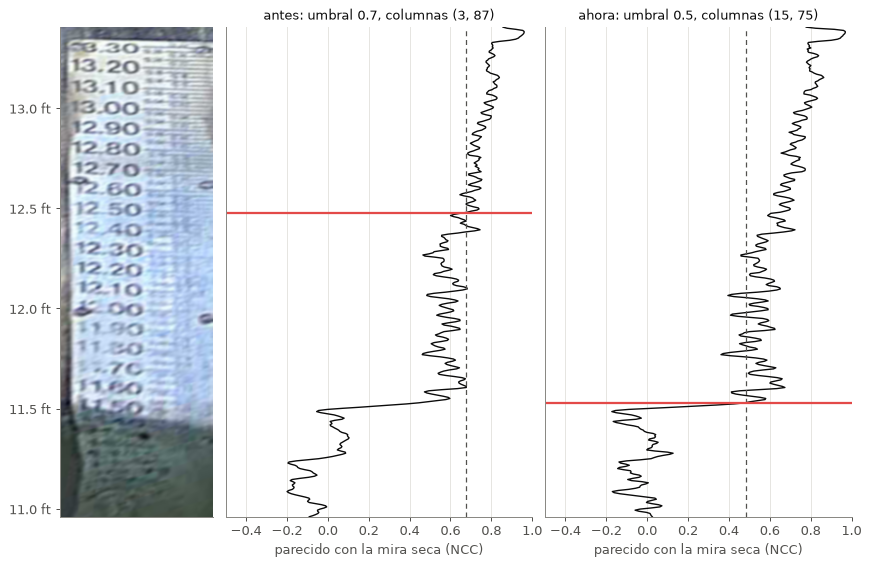

In [16]:
foto_umbral = "NY_Owasco_Lake_near_Auburn_Staff___2025-10-10T16-00-09Z.jpg"
activar(1)
R_u = T.enderezar(gris(leer(foto_umbral)))
dx_u, dy_u, s_u = registrar(R_u)
R_u = alinear(R_u, dx_u, dy_u)
filas_u = np.arange(int(T.fila_de(NIVEL_MAX_AGUA)), int(T.fila_de(10.95 * PIE)))
curva_u = parecido_con_seca(R_u, filas_u)
corte_u = primer_hueco(R_u, s_u)
print("Registro de esta foto con COLUMNAS (3, 87): dx %d (tope: +-3). Corte: %.2f ft" % (dx_u, T.nivel_de(corte_u) / PIE))

COLUMNAS = (15, 75)     # [v3] mas margen para el registro
FRACCION = 0.5          # [v3] la mira seca no debe quedar en el umbral
HUECO_CM = 3.0          # [v3] una sombra o una mancha duran menos
PARECIDO_SECO_MIN = 0.85    # [v3] las fotos en infrarrojo, por debajo, no se leen bien
ENCUADRES[1]["minimo"], ENCUADRES[1]["min_busqueda"] = 10.95 * PIE, 10.85 * PIE     # [v3] el pie de la placa esta gastado
for n in ["ventanas", "curva_espejo", "espejo"]:     # sus valores por defecto toman las columnas nuevas; el codigo es el mismo
    exec(ULTIMA_02[n], globals())
activar(1)
R_u2 = T.enderezar(gris(leer(foto_umbral)))
dx_u2, dy_u2, s_u2 = registrar(R_u2)
R_u2 = alinear(R_u2, dx_u2, dy_u2)
curva_u2 = parecido_con_seca(R_u2, filas_u)
corte_u2 = primer_hueco(R_u2, s_u2)
print("Con los nuevos valores: dx %d, corte %.2f ft. A ojo, el agua esta en ~11.45 ft" % (dx_u2, T.nivel_de(corte_u2) / PIE))

fig, ax = plt.subplots(1, 3, figsize=(10, 6.4), sharey=True, gridspec_kw={"width_ratios": [0.5, 1, 1], "wspace": 0.05})
ax[0].imshow(rgb(T.enderezar(leer(foto_umbral))), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic"); ax[0].set_xticks([])
ax[0].set_yticks([T.fila_de(c * PIE) for c in niveles]); ax[0].set_yticklabels(["%.1f ft" % c for c in niveles])
for a, c, u, cor, tt in [(ax[1], curva_u, 0.7 * s_u, corte_u, "antes: umbral 0.7, columnas (3, 87)"), (ax[2], curva_u2, 0.5 * s_u2, corte_u2, "ahora: umbral 0.5, columnas (15, 75)")]:
    a.plot(c, filas_u, color=TINTA, lw=1.1); a.axvline(u, color=TINTA2, lw=1, ls=(0, (4, 3))); a.axhline(cor, color=ROJO, lw=1.8)
    a.set_xlim(-0.5, 1); a.set_xlabel("parecido con la mira seca (NCC)"); a.set_title(tt, color=TINTA, fontsize=10); a.grid(axis="x", color=REJILLA, lw=0.8); a.set_axisbelow(True); a.tick_params(axis="y", length=0)
ax[0].set_ylim(filas_u[-1], filas_u[0])
fig.subplots_adjust(left=0.1, right=0.98, top=0.94, bottom=0.09)

df_c3 = medir_por_encuadres(fotos_s)
control.append(control_a_ojo("+ parametros", encuadre_de_control))
display(pd.DataFrame(control).set_index("regla"))


def es_infrarrojo(a):
    # solo para esta tabla: en infrarrojo la foto casi no tiene saturacion
    return float(np.median(cv2.cvtColor(leer(a)[1300:2300, 1000:1300], cv2.COLOR_BGR2HSV)[..., 1])) < 3


with ThreadPoolExecutor(8) as ex:
    df_c3["infrarrojo"] = list(ex.map(es_infrarrojo, df_c3.archivo))
df_c3[df_c3.parecido_seco > 0.01].groupby("infrarrojo").agg(fotos=("archivo", "size"), parecido_mediano=("parecido_seco", "median"), minimo=("parecido_seco", "min"), maximo=("parecido_seco", "max"), con_lectura=("nivel_bruto_cm", lambda s: int(s.notna().sum()))).round(2)